# AI-Based Student Performance Prediction System
## Comprehensive Data Analysis, Exploratory Modeling & Machine Learning Pipeline

**Dataset Source:** UCI Machine Learning Repository — Student Performance Data Set (*Cortez & Silva, 2008*)  
**Primary Course Target:** Final Math Grade (`G3`, numeric scale: 0–20)  
**Objective:** Analyze socio-demographic, familial, and academic behavioral features to predict student performance and identify key factors impacting educational success without target data leakage.

> **Educational Disclaimer:** Predictions generated by this system are statistical estimates intended strictly for academic pattern discovery and early-support guidance. They are never definitive assessments of student ability.


In [1]:
import os
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10


## 1. Dataset Loading and Quality Audit

In [2]:
# Robust dataset path detection (works locally and in Kaggle environments)
data_candidates = list(Path("/kaggle/input").glob("**/student-mat.csv")) + [Path("data/student-mat.csv")]
DATA_PATH = next((p for p in data_candidates if p.exists()), Path("data/student-mat.csv"))
print(f"Loading dataset from: {DATA_PATH}")
df = pd.read_csv(DATA_PATH, sep=";")

print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Missing Values Total: {df.isnull().sum().sum()}")
print(f"Duplicate Rows: {df.duplicated().sum()}")
df.head()


Dataset Dimensions: 395 rows, 33 columns
Missing Values Total: 0
Duplicate Rows: 0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 2. Target Variable Analysis (`G3`) and Leakage Prevention

In the UCI dataset:
- `G1` = First period grade (0-20)
- `G2` = Second period grade (0-20)
- `G3` = Final grade (0-20) [Target Variable]

To construct a realistic **early-warning** prediction system and strictly prevent **target leakage**, we exclude `G1` and `G2` from the predictor features. This forces the model to rely genuinely on socio-economic, study habit, and behavioral features.


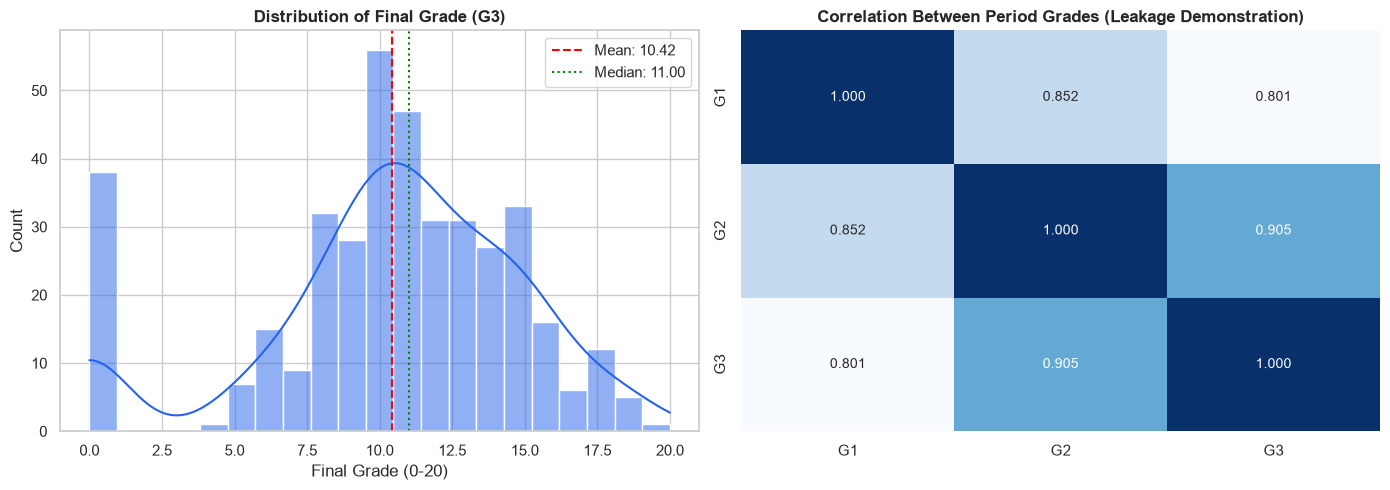

G3 Descriptive Statistics:
count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Target distribution
sns.histplot(df["G3"], kde=True, ax=axes[0], color="#2563eb", bins=21)
axes[0].axvline(df["G3"].mean(), color="red", linestyle="--", label=f"Mean: {df['G3'].mean():.2f}")
axes[0].axvline(df["G3"].median(), color="green", linestyle=":", label=f"Median: {df['G3'].median():.2f}")
axes[0].set_title("Distribution of Final Grade (G3)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Final Grade (0-20)")
axes[0].legend()

# Correlation with G1 and G2 showing extreme correlation (leakage risk)
grade_corr = df[["G1", "G2", "G3"]].corr()
sns.heatmap(grade_corr, annot=True, cmap="Blues", fmt=".3f", ax=axes[1], cbar=False)
axes[1].set_title("Correlation Between Period Grades (Leakage Demonstration)", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

print("G3 Descriptive Statistics:")
print(df["G3"].describe())


## 3. Exploratory Data Analysis: Key Behavioral and Academic Drivers

C:\Users\KARTHICK\AppData\Local\Temp\ipykernel_33380\3313926142.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, x="studytime_label", y="G3", order=list(study_map.values()), ax=axes[0, 0], palette="Blues")
C:\Users\KARTHICK\AppData\Local\Temp\ipykernel_33380\3313926142.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, x="failures", y="G3", ax=axes[0, 1], palette="Reds_r")
C:\Users\KARTHICK\AppData\Local\Temp\ipykernel_33380\3313926142.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, x="high

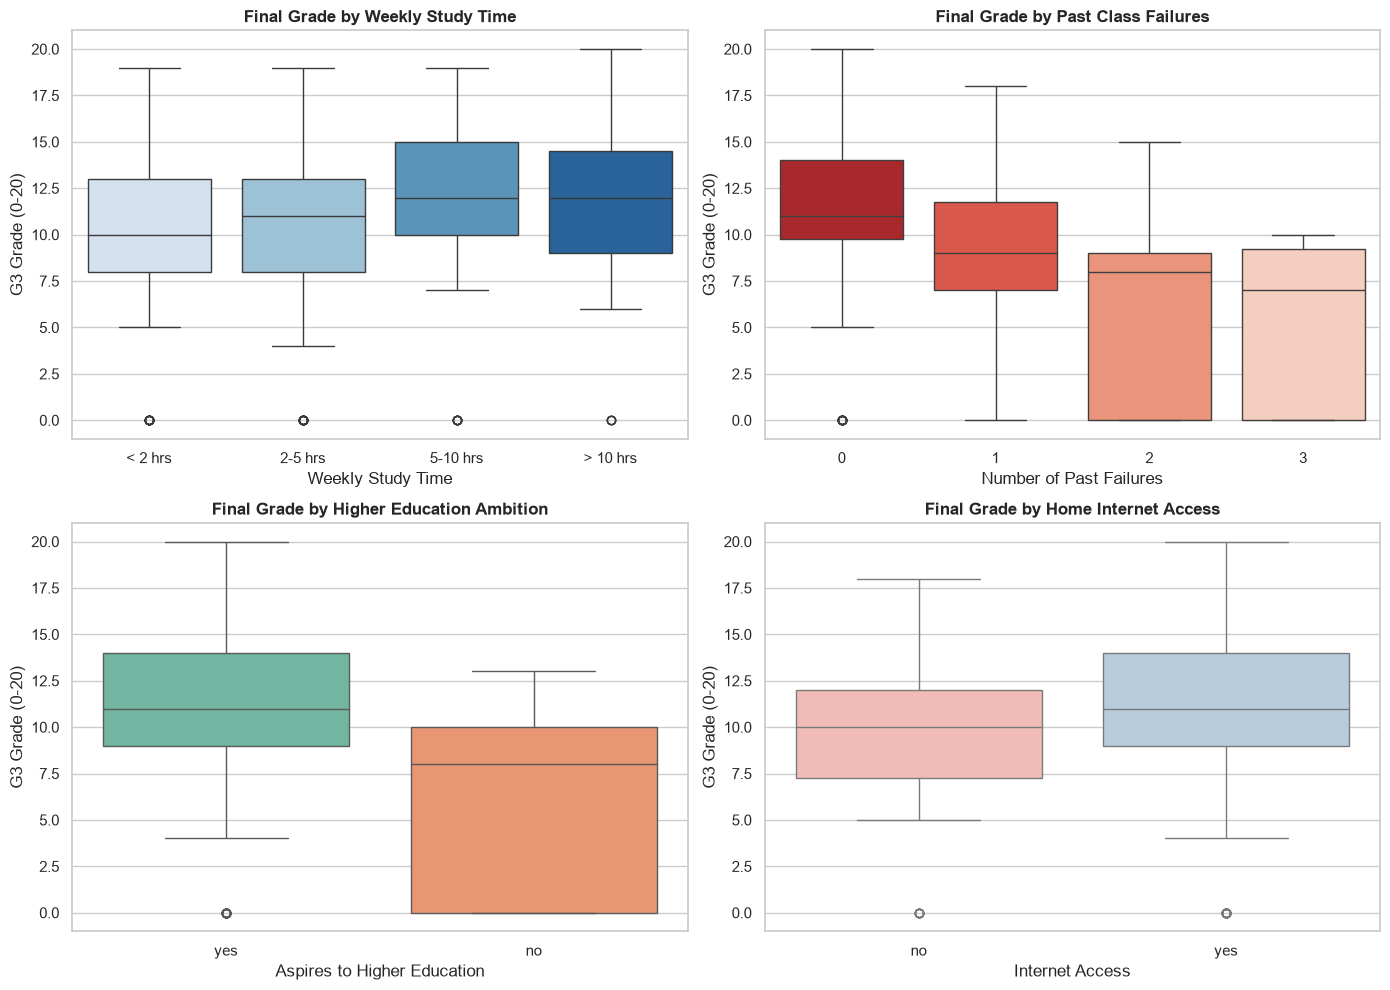

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Study time vs G3
study_map = {1: "< 2 hrs", 2: "2-5 hrs", 3: "5-10 hrs", 4: "> 10 hrs"}
df_plot = df.copy()
df_plot["studytime_label"] = df_plot["studytime"].map(study_map)
sns.boxplot(data=df_plot, x="studytime_label", y="G3", order=list(study_map.values()), ax=axes[0, 0], palette="Blues")
axes[0, 0].set_title("Final Grade by Weekly Study Time", fontweight="bold")
axes[0, 0].set_xlabel("Weekly Study Time")
axes[0, 0].set_ylabel("G3 Grade (0-20)")

# Failures vs G3
sns.boxplot(data=df_plot, x="failures", y="G3", ax=axes[0, 1], palette="Reds_r")
axes[0, 1].set_title("Final Grade by Past Class Failures", fontweight="bold")
axes[0, 1].set_xlabel("Number of Past Failures")
axes[0, 1].set_ylabel("G3 Grade (0-20)")

# Higher Education Ambition vs G3
sns.boxplot(data=df_plot, x="higher", y="G3", ax=axes[1, 0], palette="Set2")
axes[1, 0].set_title("Final Grade by Higher Education Ambition", fontweight="bold")
axes[1, 0].set_xlabel("Aspires to Higher Education")
axes[1, 0].set_ylabel("G3 Grade (0-20)")

# Internet Access vs G3
sns.boxplot(data=df_plot, x="internet", y="G3", ax=axes[1, 1], palette="Pastel1")
axes[1, 1].set_title("Final Grade by Home Internet Access", fontweight="bold")
axes[1, 1].set_xlabel("Internet Access")
axes[1, 1].set_ylabel("G3 Grade (0-20)")

plt.tight_layout()
plt.show()


## 4. Feature Preparation and Pipeline Construction

In [5]:
# Separate predictors and target (excluding G1, G2, G3)
feature_cols = [c for c in df.columns if c not in ["G1", "G2", "G3"]]
X = df[feature_cols].copy()
y = df["G3"].copy()

numeric_cols = [
    "age", "Medu", "Fedu", "traveltime", "studytime", "failures",
    "famrel", "freetime", "goout", "Dalc", "Walc", "health", "absences"
]

categorical_cols = [
    "school", "sex", "address", "famsize", "Pstatus", "Mjob",
    "Fjob", "reason", "guardian", "schoolsup", "famsup", "paid",
    "activities", "nursery", "higher", "internet", "romantic"
]

print(f"Total Predictors: {len(feature_cols)} ({len(numeric_cols)} numeric, {len(categorical_cols)} categorical)")

# Train/Test Split with fixed random seed
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print(f"Training set shape: {X_train.shape}, Test set shape: {X_test.shape}")

# Define preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
    ],
    remainder="drop"
)


Total Predictors: 30 (13 numeric, 17 categorical)
Training set shape: (316, 30), Test set shape: (79, 30)


## 5. Model Training and 5-Fold Cross-Validation Comparison

We train and compare:
1. **Baseline Regressor:** Dummy model predicting mean training grade.
2. **Linear Regression:** Standard unregularized OLS model.
3. **Ridge Regression:** L2 regularized linear model (alpha=10.0).
4. **Random Forest Regressor:** Ensemble of decision trees with depth and sample constraints.
5. **Gradient Boosting Regressor:** Sequential boosting of weak learners.


In [6]:
candidates = {
    "Baseline (Mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=10.0, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=5, min_samples_split=5, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=80, max_depth=3, learning_rate=0.05, random_state=42)
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
comparison_records = []
fitted_pipelines = {}

for name, model in candidates.items():
    pipe = Pipeline(steps=[("prep", preprocessor), ("model", model)])
    
    # 5-Fold Cross-Validation on X_train only
    cv_mae_scores = -cross_val_score(pipe, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error")
    cv_r2_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="r2")
    
    cv_mae = float(np.mean(cv_mae_scores))
    cv_r2 = float(np.mean(cv_r2_scores))
    
    # Fit on full training set
    pipe.fit(X_train, y_train)
    fitted_pipelines[name] = pipe
    
    # Evaluate on held-out test set
    preds = pipe.predict(X_test)
    test_mae = mean_absolute_error(y_test, preds)
    test_rmse = np.sqrt(mean_squared_error(y_test, preds))
    test_r2 = r2_score(y_test, preds)
    
    comparison_records.append({
        "Model": name,
        "CV MAE": round(cv_mae, 3),
        "CV R2": round(cv_r2, 3),
        "Test MAE": round(test_mae, 3),
        "Test RMSE": round(test_rmse, 3),
        "Test R2": round(test_r2, 3)
    })

comparison_df = pd.DataFrame(comparison_records)
comparison_df


,Model,CV MAE,CV R2,Test MAE,Test RMSE,Test R2
0,Baseline (Mean),3.403,-0.035,3.646,4.550,-0.010
1,Linear Regression,3.523,-0.092,3.395,4.196,0.141
2,Ridge Regression,3.417,-0.016,3.374,4.180,0.148
3,Random Forest,2.971,0.207,3.173,3.949,0.239
4,Gradient Boosting,3.052,0.198,3.171,3.929,0.247


## 6. Model Comparison Visualizations

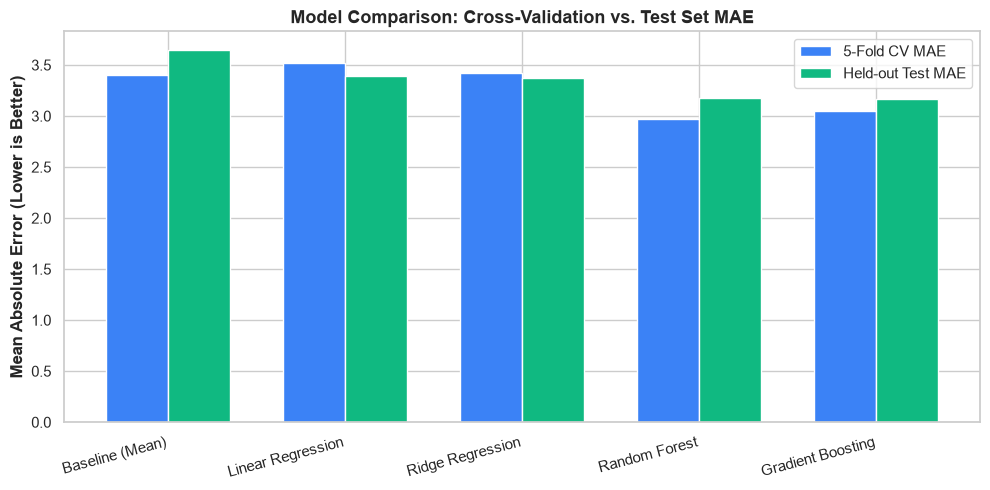

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(comparison_df))
width = 0.35

ax.bar(x - width/2, comparison_df["CV MAE"], width, label="5-Fold CV MAE", color="#3b82f6")
ax.bar(x + width/2, comparison_df["Test MAE"], width, label="Held-out Test MAE", color="#10b981")

ax.set_ylabel("Mean Absolute Error (Lower is Better)", fontweight="bold")
ax.set_title("Model Comparison: Cross-Validation vs. Test Set MAE", fontsize=13, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(comparison_df["Model"], rotation=15, ha="right")
ax.legend()
plt.tight_layout()
plt.show()


## 7. Selected Model Evaluation: Random Forest Regressor

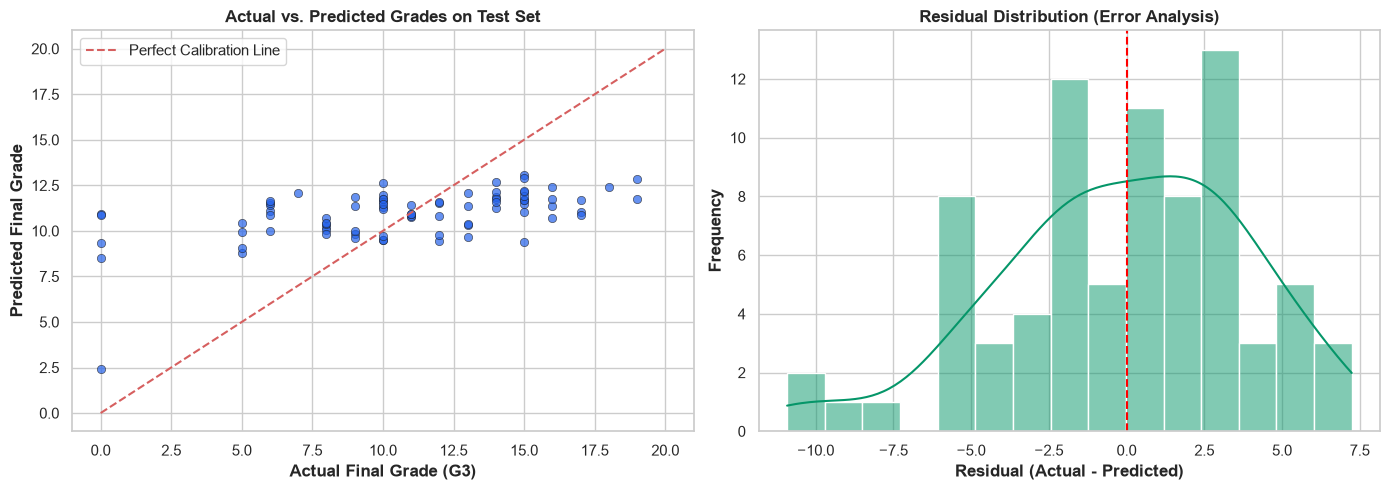

In [8]:
best_pipeline = fitted_pipelines["Random Forest"]
best_preds = best_pipeline.predict(X_test)

residuals = y_test - best_preds

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
axes[0].scatter(y_test, best_preds, color="#2563eb", alpha=0.7, edgecolors="k", linewidths=0.5)
axes[0].plot([0, 20], [0, 20], "r--", linewidth=1.5, label="Perfect Calibration Line")
axes[0].set_xlabel("Actual Final Grade (G3)", fontweight="bold")
axes[0].set_ylabel("Predicted Final Grade", fontweight="bold")
axes[0].set_title("Actual vs. Predicted Grades on Test Set", fontweight="bold")
axes[0].legend()

# Residual Distribution
sns.histplot(residuals, kde=True, ax=axes[1], color="#059669", bins=15)
axes[1].axvline(0, color="red", linestyle="--", linewidth=1.5)
axes[1].set_xlabel("Residual (Actual - Predicted)", fontweight="bold")
axes[1].set_ylabel("Frequency", fontweight="bold")
axes[1].set_title("Residual Distribution (Error Analysis)", fontweight="bold")

plt.tight_layout()
plt.show()


## 8. Feature Importance Analysis

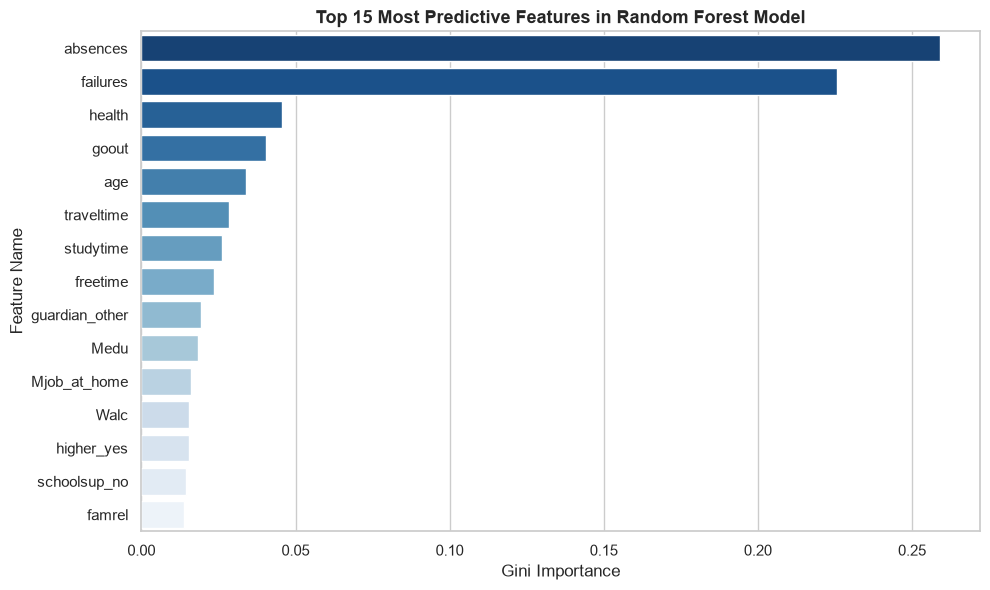

In [9]:
rf_model = best_pipeline.named_steps["model"]
prep = best_pipeline.named_steps["prep"]
cat_encoded = prep.named_transformers_["cat"].get_feature_names_out(categorical_cols)
all_feat_names = numeric_cols + list(cat_encoded)

fi_series = pd.Series(rf_model.feature_importances_, index=all_feat_names).sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=fi_series.values, y=fi_series.index, hue=fi_series.index, palette="Blues_r", legend=False)
plt.title("Top 15 Most Predictive Features in Random Forest Model", fontsize=13, fontweight="bold")
plt.xlabel("Gini Importance")
plt.ylabel("Feature Name")
plt.tight_layout()
plt.show()


## 9. Model Pipeline Serialization & Inference Verification

In [10]:
os.makedirs("models", exist_ok=True)
joblib.dump(best_pipeline, "models/student_model.joblib")
print("Model pipeline saved to models/student_model.joblib")

# Reload and test inference
loaded_pipe = joblib.load("models/student_model.joblib")
sample_test = X_test.iloc[0:1]
sample_pred = loaded_pipe.predict(sample_test)[0]
actual_val = y_test.iloc[0]

print(f"Inference Verification:")
print(f"  Actual Grade:    {actual_val}")
print(f"  Predicted Grade: {sample_pred:.2f}")
print("Pipeline verified successfully!")


Model pipeline saved to models/student_model.joblib
Inference Verification:
  Actual Grade:    10
  Predicted Grade: 9.52
Pipeline verified successfully!
